# MAST pulse batching

Generalizes `MAST_pulse.ipynb` into a function that takes a shot id (or a list of them) plus every parameter that a decision is made for and runs tmtx loops

In [1]:
# campaigns M5-M9, 2004-2013
import numpy as np
import requests
import xarray as xr
from scipy.interpolate import RegularGridInterpolator
import matplotlib.pyplot as plt

import os
import sys
import copy

BASE_URL = 'https://mastapp.site'

tokamaker_python_path = os.getenv('OFT_ROOTPATH')
if tokamaker_python_path is not None:
    sys.path.append(os.path.join(tokamaker_python_path, 'python'))
from OpenFUSIONToolkit import OFT_env
from OpenFUSIONToolkit.TokaMaker import TokaMaker
from OpenFUSIONToolkit.TokaMaker.meshing import load_gs_mesh
from OpenFUSIONToolkit.TokaMaker.pulse_design import TokaMaker_TORAX, BASE_CONFIG
import torax

def getOftEnv(nthreads=2):
    # OFT_env only allows one instance per kernel, reuse it if this kernel already made one
    return OFT_env.instance if hasattr(OFT_env, 'instance') else OFT_env(nthreads=nthreads)

In [2]:
def openShotGroup(shotId, group, level=1):
    """
    Opens a diagnostic group (efm, ayc, anb, summary, etc) for a shot,
    download of pulse only happen upon a read
    """
    path = f'json/shots/{shotId}' if level == 1 else f'json/level2/shots/{shotId}'
    try:
        response = requests.get(f'{BASE_URL}/{path}')
        response.raise_for_status()
        shot = response.json()
        shotUrl = shot['url'].replace('s3:/', shot['endpoint_url'])
        return xr.open_zarr(shotUrl, group=group)
    except requests.RequestException as e:
        print(f'failed to fetch shot {shotId}: {e}')
        return None

def openThomsonGroup(shotId, level=1):
    try:
        return openShotGroup(shotId, 'ayc', level=level)
    except KeyError:
        try:
            return openShotGroup(shotId, 'atm', level=level)
        except KeyError:
            raise KeyError(f'shot {shotId} has no Thomson group under ayc or atm')

## Geometry and profile helpers

In [3]:
def buildGeqdsk(eq):
    # Builds a dict matching read_eqdsk()'s keys from an efm equilibrium slice.
    validCols = ~np.isnan(eq['psirz'].values).any(axis=0)
    gridR, gridZ = eq['gridr'].values, eq['gridz'].values
    lcfsR, lcfsZ = eq['lcfs_r'].values, eq['lcfs_z'].values
    lcfsValid = ~np.isnan(lcfsR) & ~np.isnan(lcfsZ)
    return {
        'nr': len(gridR),
        'nz': len(gridZ),
        'rdim': float(gridR.max() - gridR.min()),
        'zdim': float(gridZ.max() - gridZ.min()),
        'rleft': float(gridR.min()),
        'zmid': float((gridZ.max() + gridZ.min()) / 2.0),
        'rcentr': float(eq['rvtor']),
        'bcentr': float(eq['bvac_val']),
        'raxis': float(eq['magnetic_axis_r']),
        'zaxis': float(eq['magnetic_axis_z']),
        'psimag': float(eq['psi_axis']),
        'psibry': float(eq['psi_boundary']),
        'ip': float(eq['plasma_current_c']),
        'fpol': eq['fpsi_c'].values,
        'pres': eq['ppsi_c'].values,
        'ffprim': eq['ffprime'].values,
        'pprime': eq['pprime'].values,
        'psirz': eq['psirz'].values[:, validCols],
        'qpsi': eq['qpsi_c'].values,
        'rzout': np.column_stack([lcfsR[lcfsValid], lcfsZ[lcfsValid]]),
        'rzlim': np.column_stack([eq['limiterr'].values, eq['limiterz'].values]),
    }

def psiNormAtMidplane(rQuery, eq):
    # Maps real-space midplane R to normalized poloidal flux using the cleaned psirz grid
    validCols = ~np.isnan(eq['psirz'].values).any(axis=0)
    gridR, gridZ = eq['gridr'].values, eq['gridz'].values
    psirzClean = eq['psirz'].values[:, validCols]
    interp = RegularGridInterpolator((gridZ, gridR), psirzClean, bounds_error=False, fill_value=None)
    # Thomson chords at Z=0
    psi = interp(np.column_stack([np.zeros_like(rQuery), rQuery]))
    return (psi - float(eq['psi_axis'])) / (float(eq['psi_boundary']) - float(eq['psi_axis']))

def rhoTorNormFromPsiNorm(psiNormQuery, eq, lastSurface=1.0):
    # Converts normalized poloidal flux to normalized toroidal flux
    psiNorm65 = eq['psi_norm'].values
    q = eq['qpsi_c'].values
    torFlux = np.concatenate([[0.0], np.cumsum(0.5 * (q[1:] + q[:-1]) * np.diff(psiNorm65))])
    torFluxNorm = torFlux / np.interp(lastSurface, psiNorm65, torFlux)
    return np.interp(np.clip(psiNormQuery, 0, 1), psiNorm65, torFluxNorm) ** 0.5

def mapThomsonToRho(shotId, refTime, eq, lastSurface=1.0):
    # Throw out broken/NaN channels, relabel measurements by flux surface in format TORAX likes
    thomson = openThomsonGroup(shotId, level=1).sel(time=refTime, method='nearest')
    r, te, ne = thomson['radius'].values, thomson['te'].values, thomson['ne'].values
    valid = ~np.isnan(r) & ~np.isnan(te) & ~np.isnan(ne)
    rho = rhoTorNormFromPsiNorm(psiNormAtMidplane(r[valid], eq), eq, lastSurface)
    return rho, te[valid], ne[valid]

def mapCxrsToRho(shotId, refTime, eq, lastSurface=1.0):
    # CXRS isnt on every shot even when the beam is, not every era has the act group
    # Fall back to Ti = Te
    try:
        act = openShotGroup(shotId, 'act', level=1)
    except KeyError:
        return None
    if act is None or 'pla_temperature' not in act.data_vars or 'pla_temperature_error' not in act.data_vars:
        return None
    cxrs = act.sel(time=refTime, method='nearest')
    r, ti, tiError = cxrs['majorradius'].values, cxrs['pla_temperature'].values, cxrs['pla_temperature_error'].values
    valid = ~np.isnan(r) & ~np.isnan(ti) & (ti > 0) & (ti < 5000) & (tiError > 0) & (tiError < 0.3 * ti)
    if not np.any(valid):
        return None
    rho = rhoTorNormFromPsiNorm(psiNormAtMidplane(r[valid], eq), eq, lastSurface)
    # CXRS only measures with a beam on, before that there are too few good channels inside the plasma
    if np.sum(rho < 1.0) < 3:
        return None
    return rho, ti[valid]

def buildNodeProfile(rho, values, rhoNodeCount=10, medianHalfWidth=0.1):
    # Running median onto a fixed rho grid, shared by every kinetic profile (Te, ne, Ti)
    # smooths noisy scattered measurements onto a clean grid
    sortOrder = np.argsort(rho)
    rhoSorted, valSorted = rho[sortOrder], values[sortOrder]
    rhoNodes = np.linspace(0.0, 1.0, rhoNodeCount)
    nodes = np.array([np.median(valSorted[np.abs(rhoSorted - x) <= medianHalfWidth]) if np.any(np.abs(rhoSorted - x) <= medianHalfWidth) else np.nan for x in rhoNodes])
    covered = ~np.isnan(nodes)
    return rhoNodes[covered], nodes[covered]

def gasPuffRate(shotId, coarseDt=0.01):
    # Need a particle rate for set_fueling. gas_injection only gives a cumulative
    # injected count, resample onto a coarser time grid before differentiating.
    # turns a running total into a rate
    ds = openShotGroup(shotId, 'gas_injection', level=2)
    try:
        t, total = ds['time'].values, ds['total_injected'].values
    except KeyError:
        raise KeyError(f'shot {shotId} gas_injection has no total_injected, only raw valve signals')
    tCoarse = np.arange(t.min(), t.max(), coarseDt) # resampled to 10 ms
    totalCoarse = np.interp(tCoarse, t, total)
    rateCoarse = np.clip(np.gradient(totalCoarse, tCoarse), 0, None)
    return dict(zip(tCoarse.tolist(), rateCoarse.tolist()))

In [4]:
channelToCoilSet = {
    'SOL': 'SOL', 'P2IL FEED': 'P2_INNER_LOWER', 'P2IU FEED': 'P2_INNER_UPPER',
    'P2OL FEED': 'P2_OUTER_LOWER', 'P2OU FEED': 'P2_OUTER_UPPER',
    'P3L FEED': 'P3_LOWER', 'P3U FEED': 'P3_UPPER',
    'P4L FEED': 'P4_LOWER', 'P4U FEED': 'P4_UPPER',
    'P5L FEED': 'P5_LOWER', 'P5U FEED': 'P5_UPPER',
    'P6L': 'P6_LOWER', 'P6U': 'P6_UPPER',
}

## Shot window

In [5]:
def loadShotWindow(shotId):
    efmGroup = openShotGroup(shotId, 'efm', level=1)
    if efmGroup is None:
        raise KeyError(f'shot {shotId} efm fetch failed, see the network error printed above')
    try:
        efm = efmGroup.load()
    except KeyError:
        raise KeyError(f'shot {shotId} has no efm group at all')
    if 'plasma_current_c' not in efm.data_vars:
        efm['plasma_current_c'] = efm['plasma_current_x']
    validTimes = efm['time'].values[~np.isnan(efm['plasma_current_c'].values)]

    # EFIT reconstruction only between startup and ramp down, poloidal beta < 0 and li > 2 when plasma is small
    try:
        efmReliable = (efm['betap'].sel(time=validTimes).values > 0) & (efm['li'].sel(time=validTimes).values < 2.0)
    except KeyError:
        raise KeyError(f'shot {shotId} efm has no derived equilibrium (betap/li missing), EFIT reconstruction looks incomplete')

    # Longest stretch of reliable slices
    reliableTimes = validTimes[efmReliable]
    reliableRuns = np.split(reliableTimes, np.where(np.diff(reliableTimes) > 2.5 * np.median(np.diff(validTimes)))[0] + 1)
    pulseWindow = max(reliableRuns, key=lambda run: run[-1] - run[0])
    tPulseStart = float(pulseWindow[0])
    tPulseEnd = float(pulseWindow[-1])
    refTime = tPulseStart
    equilibrium = efm.sel(time=refTime, method='nearest')

    ayc = openThomsonGroup(shotId, level=1)[['te', 'ne', 'radius']].load()
    teValidTimeMask = ~np.isnan(ayc['te'].values).all(axis=1)
    thomsonValidTimes = ayc['time'].values[teValidTimeMask]
    thomsonRefTime = float(thomsonValidTimes[np.argmin(np.abs(thomsonValidTimes - refTime))])

    return efm, validTimes, tPulseStart, tPulseEnd, refTime, equilibrium, ayc, thomsonValidTimes, thomsonRefTime

def loadBeamPower(shotId, tPulseStart, tPulseEnd, powerThresholdMw=0.01):
    """
    NBI power trajectory. None for Ohmic shots or shots with no beam diagnostic. tot_sum_power 
    sums SS and SW so this check covers every supported heating type (SS Beam, SW Beam, 2 Beams). 
    Threshold sits above noise floor on confirmed Ohmic shots (sub 1 kW) and below real beam 
    power (100s of kW+).
    """
    try:
        anb = openShotGroup(shotId, 'anb', level=1)
    except KeyError:
        return None
    if anb is None or 'tot_sum_power' not in anb.data_vars:
        return None
    power = anb['tot_sum_power'].sel(time=slice(tPulseStart, tPulseEnd))
    if np.nanmax(power.values) < powerThresholdMw:
        return None
    return {float(t): float(p) * 1e6 for t, p in zip(power['time'].values, power.values) if not np.isnan(p)}

## Seed equilibria

In [6]:
def buildSeedEquilibria(mygs, shotId, efm, seedTimes, channelToCoilSet, coilBoundAmps, fluxWeightCandidates=(10.0, 1.0, 0.1)):
    mygs.set_coil_bounds({name: [-coilBoundAmps, coilBoundAmps] for name in mygs.coil_sets})  # Loose bounds, not real coil limits

    # Generate and save one seed eqdsk per seed time
    seedFiles = []
    os.makedirs('seeds', exist_ok=True)

    # Same PF current record for every seed time, get once
    pfActiveCurrents = openShotGroup(shotId, 'pf_active', level=2)

    for i, seedTime in enumerate(seedTimes):
        seedEq = efm.sel(time=seedTime, method='nearest')
        seedGeqdsk = buildGeqdsk(seedEq)

        regTerms = []
        for channelName, coilSetName in channelToCoilSet.items():
            realCurrentAmps = float(pfActiveCurrents['coil_current'].sel(current_channel=channelName).sel(time=seedTime, method='nearest'))
            netTurns = mygs.coil_sets[coilSetName]['net_turns']
            targetPerTurn = 0.5 * realCurrentAmps if coilSetName == 'SOL' else realCurrentAmps / netTurns
            regTerms.append(mygs.coil_reg_term({coilSetName: 1.0}, target=targetPerTurn, weight=1.0e-2))
        mygs.set_coil_reg(reg_terms=regTerms)

        mygs.set_targets(Ip=abs(seedGeqdsk['ip']), pax=abs(seedGeqdsk['pres'][0]))

        rzout = seedGeqdsk['rzout']
        r0 = float(seedEq['magnetic_axis_r'])
        z0 = float(seedEq['magnetic_axis_z'])
        a = float((rzout[:, 0].max() - rzout[:, 0].min()) / 2.0)
        kappa = float((rzout[:, 1].max() - rzout[:, 1].min()) / (2.0 * a))

        # A plasma this early has almost no flux depth between axis and boundary
        for attempt, weight in enumerate(fluxWeightCandidates):
            # Set boundary flux to EFIT value so seed has physical absolute flux
            mygs.set_psi_constraints(rzout, np.full(len(rzout), float(seedEq['psi_boundary'])), weights=np.full(len(rzout), weight))
            mygs.init_psi(r0=r0, z0=z0, a=a, kappa=kappa, delta=0.0)
            try:
                mygs.solve()
                break
            except Exception as e:
                if attempt == len(fluxWeightCandidates) - 1:
                    raise
                print(f'seed {i} failed at flux weight={weight}, retrying at {fluxWeightCandidates[attempt + 1]}: {e}')

        seedPath = f'seeds/seed_{i}.eqdsk'
        mygs.save_eqdsk(seedPath, cocos=2)  # save_eqdsk defaults to cocos=7, TokaMaker_TORAX assumes cocos=2 internally
        seedFiles.append(seedPath)

    return seedFiles

def pickLastSurfaceFactor(seedFiles, candidates=(0.95, 0.9, 0.85)):
    # TORAX cant build flux surface geometry to separatrix of diverted plasmas, use largest last surface factor it accepts
    # TGLF surrogate
    # BASE_CONFIG['transport'] = {**{k: v for k, v in BASE_CONFIG['transport'].items() if k not in ('include_ITG', 'include_TEM', 'include_ETG', 'avoid_big_negative_s')}, 'model_name': 'tglfnn-ukaea', 'machine': 'multimachine'}
    for factor in candidates:
        try:
            for seedFile in seedFiles:
                geometryCheck = copy.deepcopy(BASE_CONFIG)
                geometryCheck['geometry'] = {'geometry_type': 'eqdsk', 'geometry_directory': os.getcwd(), 'last_surface_factor': factor, 'Ip_from_parameters': False, 'geometry_file': seedFile, 'cocos': 2}
                torax.ToraxConfig.from_dict(geometryCheck)
            return factor
        except Exception:
            continue
    raise ValueError('TORAX rejects the seed equilibria at every last surface factor tried')

## Initial profiles and edge conditions

In [7]:
def buildInitialProfiles(shotId, thomsonRefTime, equilibrium, lastSurface, efm, validTimes, tPulseStart, tPulseEnd,
                          edgeTe, edgeDensityFraction, gasPuffCoarseDt=0.01, rhoNodeCount=10, medianHalfWidth=0.1):
    # Initial kinetic profiles, Te/ne from the first Thomson slice in the window
    rhoInit, teInit, neInit = mapThomsonToRho(shotId, thomsonRefTime, equilibrium, lastSurface)

    gasPuffSTotal = gasPuffRate(shotId, coarseDt=gasPuffCoarseDt)

    # Edge conditions from constants, density is fixed fraction of Greenwald density from Ip and EFIT minor radius
    tEfm = validTimes[(validTimes >= tPulseStart) & (validTimes <= tPulseEnd)]
    aMinor = np.array([(np.nanmax(efm.sel(time=t)['lcfs_r'].values) - np.nanmin(efm.sel(time=t)['lcfs_r'].values)) / 2.0 for t in tEfm])
    ipEfm = np.abs(efm['plasma_current_c'].sel(time=tEfm).values)
    greenwaldDensity = ipEfm / 1e6 / (np.pi * aMinor ** 2) * 1e20
    edgeTeBc = {float(t): edgeTe for t in tEfm}
    edgeNeBc = {float(t): float(edgeDensityFraction * n) for t, n in zip(tEfm, greenwaldDensity)}

    # Drop channels outside the last surface where rho > 1, convert Te to keV
    insidePlasma = rhoInit < 1.0
    rhoNodes, teNodes = buildNodeProfile(rhoInit[insidePlasma], teInit[insidePlasma] / 1000.0, rhoNodeCount, medianHalfWidth)
    _, neNodes = buildNodeProfile(rhoInit[insidePlasma], neInit[insidePlasma], rhoNodeCount, medianHalfWidth)
    neProfile = {0.0: {float(r): float(n) for r, n in zip(rhoNodes, neNodes)}}
    teProfile = {0.0: {float(r): float(t) for r, t in zip(rhoNodes, teNodes)}}

    # CXRS Ti where the shot and era have it, Te stands in otherwise same as the edge value below
    cxrs = mapCxrsToRho(shotId, thomsonRefTime, equilibrium, lastSurface)
    if cxrs is not None:
        rhoTi, tiInit = cxrs
        insideTi = rhoTi < 1.0
        rhoTiNodes, tiNodes = buildNodeProfile(rhoTi[insideTi], tiInit[insideTi] / 1000.0, rhoNodeCount, medianHalfWidth)
        tiProfile = {0.0: {float(r): float(t) for r, t in zip(rhoTiNodes, tiNodes)}}
    else:
        tiProfile = teProfile

    return neProfile, teProfile, tiProfile, edgeNeBc, edgeTeBc, gasPuffSTotal

## Compare to experiment

In [8]:
def compareToExperiment(tmtx, efm, ayc, validTimes, thomsonValidTimes, tPulseStart, tPulseEnd, lastSurface, plot=True, verbose=True):
    # Experimental timestamps inside simulated window
    timeSources = {
        'EFIT (efm)': validTimes,
        'core Thomson (ayc)': thomsonValidTimes,
    }
    if verbose:
        for label, times in timeSources.items():
            inWindow = times[(times >= tPulseStart) & (times <= tPulseEnd)]
            print(f'{label:20s} {len(inWindow):5d} timestamps, median step {1e3 * np.median(np.diff(inWindow)):.2f} ms')
        txTimes = tmtx._data_tree.profiles.T_e.coords['time'].values
        print(f'{"TORAX output":20s} {len(txTimes):5d} timestamps')
        print(f'{"TokaMaker solves":20s} {len(tmtx.results["psi_lcfs_tm"]["x"]):5d} timestamps')

    # Core Thomson Te/ne at every measurement time from channel nearest to magnetic axis inside the LCFS
    txTe = tmtx._data_tree.profiles.T_e
    txNe = tmtx._data_tree.profiles.n_e

    compareTimes = thomsonValidTimes[(thomsonValidTimes >= tPulseStart) & (thomsonValidTimes <= tPulseEnd)]
    usedTimes, coreRho, teMeasured, teSimulated, neMeasured, neSimulated = [], [], [], [], [], []
    for t in compareTimes:
        eq = efm.sel(time=t, method='nearest')
        thomsonNow = ayc.sel(time=t)
        r, te, ne = thomsonNow['radius'].values, thomsonNow['te'].values, thomsonNow['ne'].values
        valid = ~np.isnan(r) & ~np.isnan(te) & ~np.isnan(ne)
        rho = rhoTorNormFromPsiNorm(psiNormAtMidplane(r[valid], eq), eq, lastSurface)
        try:
            inside = np.where(rho < 1.0)[0]
            core = inside[np.argmin(rho[inside])]
        except ValueError:
            continue
        usedTimes.append(float(t))
        coreRho.append(rho[core])
        teMeasured.append(te[valid][core] / 1000.0)
        neMeasured.append(ne[valid][core])
        # TORAX output at same time and rho interpolated from output grid
        teSimulated.append(float(txTe.interp(time=t, rho_norm=rho[core])))
        neSimulated.append(float(txNe.interp(time=t, rho_norm=rho[core])))

    usedTimes, coreRho = np.array(usedTimes), np.array(coreRho)
    teMeasured, teSimulated = np.array(teMeasured), np.array(teSimulated)
    neMeasured, neSimulated = np.array(neMeasured), np.array(neSimulated)

    if verbose:
        print('time [s]   rho    measured Te [keV]   simulated Te [keV]')
        for k in range(0, len(usedTimes), max(1, len(usedTimes) // 10)):
            print(f'{usedTimes[k]:7.3f}  {coreRho[k]:5.2f}  {teMeasured[k]:12.3f}  {teSimulated[k]:15.3f}')

    if plot:
        fig, ax = plt.subplots(figsize=(8, 4))
        ax.plot(usedTimes, teMeasured, 'k.', label='Thomson (measured)')
        ax.plot(usedTimes, teSimulated, 'r-', label='TORAX (simulated)')
        ax.set_ylabel('core Te [keV]')
        ax.legend()

        fig, ax = plt.subplots(figsize=(8, 4))
        ax.plot(usedTimes, neMeasured, 'k.', label='Thomson (measured)')
        ax.plot(usedTimes, neSimulated, 'r-', label='TORAX (simulated)')
        ax.set_ylabel('core ne [1e19 m^-3]')
        ax.legend()

    teRms = float(np.sqrt(np.mean((teMeasured - teSimulated) ** 2))) if len(teMeasured) else float('nan')
    neRms = float(np.sqrt(np.mean((neMeasured - neSimulated) ** 2))) if len(neMeasured) else float('nan')

    return {
        'times': usedTimes, 'coreRho': coreRho,
        'teMeasured': teMeasured, 'teSimulated': teSimulated, 'teRms': teRms,
        'neMeasured': neMeasured, 'neSimulated': neSimulated, 'neRms': neRms,
    }

In [9]:
def coreEdgeVolAvg(tmtx, fieldName, volAvgField, t, edgeRho=0.98):
    # Simulated core (rho=0), edge (rho=edgeRho), and TORAX's volume average
    field = getattr(tmtx._data_tree.profiles, fieldName)
    core = float(field.interp(time=t, rho_norm=0.0))
    edge = float(field.interp(time=t, rho_norm=edgeRho))
    volAvg = tmtx._extract_tx_scalar(tmtx._data_tree, volAvgField, t)
    return core, volAvg, edge

def measuredCoreEdgeVolAvg(rho, values, tmtx, t, edgeRho=0.98):
    # Core/edge from the smoothed node profile, volume average weighted by TORAX's dV/drho
    # Measured and simulated averages use the same flux surface volumes
    rhoNodes, valNodes = buildNodeProfile(rho, values, rhoNodeCount=10, medianHalfWidth=0.1)
    if len(rhoNodes) < 2:
        return None, None, None
    core = float(valNodes[0])
    edge = float(np.interp(edgeRho, rhoNodes, valNodes))
    vpr = tmtx._data_tree.profiles.vpr.interp(time=t)
    vprRho = vpr['rho_norm'].values
    volAvg = float(np.trapezoid(np.interp(vprRho, rhoNodes, valNodes) * vpr.values, vprRho) / np.trapezoid(vpr.values, vprRho))
    return core, volAvg, edge

def plotKineticComparison(simSeries, measSeries, ylabel, title, savepath=None):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    panels = [('Core', 'core'), ('Volume avg', 'volAvg'), ('Edge', 'edge')]
    for ax, (panelTitle, key) in zip(axes, panels):
        ax.plot(measSeries['time'], measSeries[key], 'k.', label='measured')
        ax.plot(simSeries['time'], simSeries[key], 'r-', label='TORAX (simulated)')
        ax.set_title(panelTitle)
        ax.set_xlabel('time [s]')
        ax.set_ylabel(ylabel)
        ax.legend(fontsize=8)
    plt.suptitle(title)
    plt.tight_layout()
    if savepath:
        fig.savefig(savepath, format='svg', bbox_inches='tight')
    plt.show()
    return fig, axes

def plotTeComparison(tmtx, efm, ayc, thomsonValidTimes, tPulseStart, tPulseEnd, lastSurface, savepath=None):
    compareTimes = thomsonValidTimes[(thomsonValidTimes >= tPulseStart) & (thomsonValidTimes <= tPulseEnd)]
    sim = {'time': [], 'core': [], 'volAvg': [], 'edge': []}
    meas = {'time': [], 'core': [], 'volAvg': [], 'edge': []}
    for t in compareTimes:
        eq = efm.sel(time=t, method='nearest')
        thomsonNow = ayc.sel(time=t)
        r, te = thomsonNow['radius'].values, thomsonNow['te'].values
        valid = ~np.isnan(r) & ~np.isnan(te)
        if np.sum(valid) < 3:
            continue
        rho = rhoTorNormFromPsiNorm(psiNormAtMidplane(r[valid], eq), eq, lastSurface)
        inside = rho < 1.0
        if np.sum(inside) < 3:
            continue
        mCore, mVolAvg, mEdge = measuredCoreEdgeVolAvg(rho[inside], te[valid][inside] / 1000.0, tmtx, float(t))
        if mCore is None:
            continue
        sCore, sVolAvg, sEdge = coreEdgeVolAvg(tmtx, 'T_e', 'T_e_volume_avg', float(t))
        sim['time'].append(float(t)); sim['core'].append(sCore); sim['volAvg'].append(sVolAvg); sim['edge'].append(sEdge)
        meas['time'].append(float(t)); meas['core'].append(mCore); meas['volAvg'].append(mVolAvg); meas['edge'].append(mEdge)
    return plotKineticComparison(sim, meas, 'T_e [keV]', 'Electron temperature: sim vs experiment', savepath)

def plotNeComparison(tmtx, efm, ayc, thomsonValidTimes, tPulseStart, tPulseEnd, lastSurface, savepath=None):
    compareTimes = thomsonValidTimes[(thomsonValidTimes >= tPulseStart) & (thomsonValidTimes <= tPulseEnd)]
    sim = {'time': [], 'core': [], 'volAvg': [], 'edge': []}
    meas = {'time': [], 'core': [], 'volAvg': [], 'edge': []}
    for t in compareTimes:
        eq = efm.sel(time=t, method='nearest')
        thomsonNow = ayc.sel(time=t)
        r, ne = thomsonNow['radius'].values, thomsonNow['ne'].values
        valid = ~np.isnan(r) & ~np.isnan(ne)
        if np.sum(valid) < 3:
            continue
        rho = rhoTorNormFromPsiNorm(psiNormAtMidplane(r[valid], eq), eq, lastSurface)
        inside = rho < 1.0
        if np.sum(inside) < 3:
            continue
        mCore, mVolAvg, mEdge = measuredCoreEdgeVolAvg(rho[inside], ne[valid][inside], tmtx, float(t))
        if mCore is None:
            continue
        sCore, sVolAvg, sEdge = coreEdgeVolAvg(tmtx, 'n_e', 'n_e_volume_avg', float(t))
        sim['time'].append(float(t)); sim['core'].append(sCore); sim['volAvg'].append(sVolAvg); sim['edge'].append(sEdge)
        meas['time'].append(float(t)); meas['core'].append(mCore); meas['volAvg'].append(mVolAvg); meas['edge'].append(mEdge)
    return plotKineticComparison(sim, meas, 'n_e [m^-3]', 'Electron density: sim vs experiment', savepath)

def plotTiComparison(tmtx, efm, shotId, thomsonValidTimes, tPulseStart, tPulseEnd, lastSurface, savepath=None):
    compareTimes = thomsonValidTimes[(thomsonValidTimes >= tPulseStart) & (thomsonValidTimes <= tPulseEnd)]
    sim = {'time': [], 'core': [], 'volAvg': [], 'edge': []}
    meas = {'time': [], 'core': [], 'volAvg': [], 'edge': []}
    for t in compareTimes:
        eq = efm.sel(time=t, method='nearest')
        cxrs = mapCxrsToRho(shotId, float(t), eq, lastSurface)
        if cxrs is None:
            continue
        rho, ti = cxrs
        inside = rho < 1.0
        if np.sum(inside) < 3:
            continue
        mCore, mVolAvg, mEdge = measuredCoreEdgeVolAvg(rho[inside], ti[inside] / 1000.0, tmtx, float(t))
        if mCore is None:
            continue
        sCore, sVolAvg, sEdge = coreEdgeVolAvg(tmtx, 'T_i', 'T_i_volume_avg', float(t))
        sim['time'].append(float(t)); sim['core'].append(sCore); sim['volAvg'].append(sVolAvg); sim['edge'].append(sEdge)
        meas['time'].append(float(t)); meas['core'].append(mCore); meas['volAvg'].append(mVolAvg); meas['edge'].append(mEdge)
    if not meas['time']:
        print('no CXRS Ti data in window, skipping Ti comparison')
        return None, None
    return plotKineticComparison(sim, meas, 'T_i [keV]', 'Ion temperature: sim vs experiment', savepath)

def plotEquilibriumComparison(tmtx, efm, savepath=None):
    tmTimes = np.array(tmtx._tm_times)
    liSim, q95Sim, psiLcfsSim = [], [], []
    for i in range(len(tmTimes)):
        try:
            if tmtx._state['Ip_tm'][i] == 0:
                raise ValueError('TokaMaker solve failed')
            equil = tmtx._state['equil'][i]
            liSim.append(equil.get_stats(li_normalization='std')['l_i'])
            q95Sim.append(abs(float(equil.get_q(psi=np.array([0.95]))[1][0])))
            psiLcfsSim.append(float(tmtx._state['psi_lcfs_tm'][i]))
        except Exception:
            liSim.append(np.nan)
            q95Sim.append(np.nan)
            psiLcfsSim.append(np.nan)

    liMeas, q95Meas, psiBoundaryMeas = [], [], []
    for t in tmTimes:
        eq = efm.sel(time=t, method='nearest')
        liMeas.append(float(eq['li']))
        q95Meas.append(float(np.interp(0.95, eq['psi_norm'].values, eq['qpsi_c'].values)))
        psiBoundaryMeas.append(float(eq['psi_boundary']))

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    axes[0].plot(tmTimes, liMeas, 'k.-', label='EFIT (measured)')
    axes[0].plot(tmTimes, liSim, 'r-', label='TokaMaker (simulated)')
    axes[0].set_title('l_i'); axes[0].set_xlabel('time [s]'); axes[0].legend(fontsize=8)

    axes[1].plot(tmTimes, q95Meas, 'k.-', label='EFIT (measured)')
    axes[1].plot(tmTimes, q95Sim, 'r-', label='TokaMaker (simulated)')
    axes[1].set_title('q95'); axes[1].set_xlabel('time [s]'); axes[1].legend(fontsize=8)

    # Fluxes per radian, flip sign and * 2 pi for Wb
    fluxMeas = -(np.array(psiBoundaryMeas) - psiBoundaryMeas[0]) * 2 * np.pi
    fluxSim = -(np.array(psiLcfsSim) - psiLcfsSim[0]) * 2 * np.pi
    axes[2].plot(tmTimes, fluxMeas, 'k.-', label='EFIT (measured)')
    axes[2].plot(tmTimes, fluxSim, 'r-', label='TokaMaker (simulated)')
    axes[2].set_title('flux consumed [Wb]'); axes[2].set_xlabel('time [s]'); axes[2].legend(fontsize=8)

    plt.suptitle('Equilibrium: sim vs experiment')
    plt.tight_layout()
    if savepath:
        fig.savefig(savepath, format='svg', bbox_inches='tight')
    plt.show()
    return fig, axes

def plotEnergyRadiationComparison(tmtx, shotId, efm, ayc, thomsonValidTimes, tPulseStart, tPulseEnd, lastSurface, savepath=None):
    # Electron stored energy from Thomson (same TORAX dV/drho as the sim) and total radiated
    # power from the bolometer, both independent of the core/vol avg/edge Te and ne panels
    compareTimes = thomsonValidTimes[(thomsonValidTimes >= tPulseStart) & (thomsonValidTimes <= tPulseEnd)]
    usedTimes, weMeas = [], []
    for t in compareTimes:
        eq = efm.sel(time=t, method='nearest')
        thomsonNow = ayc.sel(time=t)
        r, te, ne = thomsonNow['radius'].values, thomsonNow['te'].values, thomsonNow['ne'].values
        valid = ~np.isnan(r) & ~np.isnan(te) & ~np.isnan(ne)
        if np.sum(valid) < 3:
            continue
        rho = rhoTorNormFromPsiNorm(psiNormAtMidplane(r[valid], eq), eq, lastSurface)
        inside = rho < 1.0
        if np.sum(inside) < 3:
            continue
        rhoNodes, teNodes = buildNodeProfile(rho[inside], te[valid][inside], rhoNodeCount=10, medianHalfWidth=0.1)
        _, neNodes = buildNodeProfile(rho[inside], ne[valid][inside], rhoNodeCount=10, medianHalfWidth=0.1)
        if len(rhoNodes) < 2:
            continue
        vpr = tmtx._data_tree.profiles.vpr.interp(time=float(t))
        vprRho = vpr['rho_norm'].values
        # 3/2 n T integrated over volume, Te in eV
        pressure = np.interp(vprRho, rhoNodes, neNodes) * np.interp(vprRho, rhoNodes, teNodes) * 1.602e-19
        usedTimes.append(float(t))
        weMeas.append(1.5 * float(np.trapezoid(pressure * vpr.values, vprRho)))

    weSim = tmtx._data_tree.scalars.W_thermal_e
    pradSim = -tmtx._data_tree.scalars.P_radiation_e

    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].plot(usedTimes, np.array(weMeas) / 1e3, 'k.', label='Thomson (measured)')
    axes[0].plot(weSim['time'].values, weSim.values / 1e3, 'r-', label='TORAX (simulated)')
    axes[0].set_title('electron stored energy'); axes[0].set_xlabel('time [s]'); axes[0].set_ylabel('W_e [kJ]'); axes[0].legend(fontsize=8)

    # Bolometer sees divertor and SOL radiation too, so the measured trace is an upper bound on core radiation
    try:
        bolometer = openShotGroup(shotId, 'abm', level=1)['prad_pol'].sel(time=slice(tPulseStart, tPulseEnd))
        axes[1].plot(bolometer['time'].values, bolometer.values / 1e6, 'k-', lw=0.5, alpha=0.6, label='bolometer (measured)')
    except (KeyError, TypeError):
        print('no bolometer prad_pol for this shot, plotting sim radiation only')
    axes[1].plot(pradSim['time'].values, pradSim.values / 1e6, 'r-', label='TORAX (simulated)')
    axes[1].set_title('radiated power'); axes[1].set_xlabel('time [s]'); axes[1].set_ylabel('P_rad [MW]'); axes[1].legend(fontsize=8)

    plt.suptitle('Stored energy and radiation: sim vs experiment')
    plt.tight_layout()
    if savepath:
        fig.savefig(savepath, format='svg', bbox_inches='tight')
    plt.show()
    return fig, axes

def plotProfileEvolutionComparison(tmtx, shotId, efm, ayc, thomsonValidTimes, lastSurface, savepath=None):
    # Same panels as tmtx.plot_profile_evolution(one_plot=True) with measured profile from 
    # nearest diagnostic time
    s = tmtx._state
    times = np.array(tmtx._tm_times)
    peakCurrent = float(np.nanmax(np.abs(efm['plasma_current_c'].values)))
    norm = plt.Normalize(vmin=times.min(), vmax=max(times.max(), times.min() + 1e-9))
    fig, axes = plt.subplots(2, 5, figsize=(25, 10))
    panels = [
        (axes[0, 0], 'n_e', 'n_e', 'n_e [m^-3]', 1.0), (axes[1, 0], 'n_i', 'n_i', 'n_i [m^-3]', 1.0),
        (axes[0, 1], 'T_e', 'T_e', 'T_e [keV]', 1.0), (axes[1, 1], 'T_i', 'T_i', 'T_i [keV]', 1.0),
        (axes[0, 2], 'ptot', 'p', 'p [Pa]', 1.0), (axes[1, 2], 'q_prof_tx', 'q', 'q', 1.0),
        (axes[0, 3], 'eta_prof', 'eta', 'eta [Ohm m]', 1.0), (axes[1, 3], 'psi_tx', 'psi', 'psi [Wb/rad]', 1.0),
        (axes[0, 4], 'j_tot', 'j_tot', 'j_tot [MA/m^2]', 1e-6), (axes[1, 4], 'j_ni', 'j_NI', 'j_NI [MA/m^2]', 1e-6),
    ]
    cxrsShot = True
    for i, t in enumerate(times):
        color = plt.cm.plasma(norm(t))
        for ax, key, title, ylabel, scale in panels:
            if i in s.get(key, {}):
                ax.plot(s[key][i]['x'], np.asarray(s[key][i]['y']) * scale, color=color, linewidth=1.5, alpha=0.8)

        eq = efm.sel(time=t, method='nearest')
        psiGrid = np.linspace(0.0, lastSurface, 200)
        rhoGrid = rhoTorNormFromPsiNorm(psiGrid, eq, lastSurface)

        tThomson = thomsonValidTimes[np.argmin(np.abs(thomsonValidTimes - t))]
        thomsonNow = ayc.sel(time=tThomson)
        r, te, ne = thomsonNow['radius'].values, thomsonNow['te'].values, thomsonNow['ne'].values
        valid = ~np.isnan(r) & ~np.isnan(te) & ~np.isnan(ne)
        rho = rhoTorNormFromPsiNorm(psiNormAtMidplane(r[valid], eq), eq, lastSurface)
        inside = rho < 1.0
        if np.sum(inside) >= 3:
            rhoNodes, teNodes = buildNodeProfile(rho[inside], te[valid][inside] / 1000.0, rhoNodeCount=11, medianHalfWidth=0.1)
            _, neNodes = buildNodeProfile(rho[inside], ne[valid][inside], rhoNodeCount=11, medianHalfWidth=0.1)
            psiNodes = np.interp(rhoNodes, rhoGrid, psiGrid)
            axes[0, 0].plot(psiNodes, neNodes, color=color, linestyle='--', linewidth=1.2)
            axes[0, 1].plot(psiNodes, teNodes, color=color, linestyle='--', linewidth=1.2)

        # Only look for CXRS again if present in first time stamp
        cxrs = mapCxrsToRho(shotId, float(t), eq, lastSurface) if cxrsShot else None
        cxrsShot = cxrs is not None
        if cxrs is not None and np.sum(cxrs[0] < 1.0) >= 3:
            rhoNodes, tiNodes = buildNodeProfile(cxrs[0][cxrs[0] < 1.0], cxrs[1][cxrs[0] < 1.0] / 1000.0, rhoNodeCount=11, medianHalfWidth=0.1)
            axes[1, 1].plot(np.interp(rhoNodes, rhoGrid, psiGrid), tiNodes, color=color, linestyle='--', linewidth=1.2)

        # EFIT q unreliable while the plasma still forming, skip below half peak current
        if abs(float(eq['plasma_current_c'])) >= 0.5 * peakCurrent:
            psiNorm65 = eq['psi_norm'].values
            keep = psiNorm65 <= lastSurface
            axes[1, 2].plot(psiNorm65[keep], eq['qpsi_c'].values[keep], color=color, linestyle='--', linewidth=1.2)

    for ax, key, title, ylabel, scale in panels:
        ax.set_title(title)
        ax.set_xlabel('psi_N')
        ax.set_ylabel(ylabel)
        ax.set_xlim([0, 1])
    axes[0, 3].set_yscale('log')
    fig.legend(handles=[plt.Line2D([], [], color='k', label='simulated'), plt.Line2D([], [], color='k', linestyle='--', label='measured')], loc='upper center', bbox_to_anchor=(0.5, 0.955), ncol=2, fontsize=12)

    sm = plt.cm.ScalarMappable(cmap=plt.cm.plasma, norm=norm)
    sm.set_array([])
    fig.colorbar(sm, ax=axes.ravel().tolist(), shrink=0.8, aspect=30, pad=0.02).set_label('time [s]', fontsize=12)
    fig.suptitle(f'Profile evolution: sim vs experiment (loop {tmtx._current_loop})', fontsize=14)
    if savepath:
        fig.savefig(savepath, format='svg', bbox_inches='tight')
    plt.show()
    return fig, axes

def plotPulseComparison(tmtx, shotId, efm, ayc, thomsonValidTimes, tPulseStart, tPulseEnd, lastSurface, figureDir='pulse_figures'):
    os.makedirs(figureDir, exist_ok=True)
    plotTeComparison(tmtx, efm, ayc, thomsonValidTimes, tPulseStart, tPulseEnd, lastSurface, savepath=f'{figureDir}/{shotId}_Te.svg')
    plotNeComparison(tmtx, efm, ayc, thomsonValidTimes, tPulseStart, tPulseEnd, lastSurface, savepath=f'{figureDir}/{shotId}_ne.svg')
    plotTiComparison(tmtx, efm, shotId, thomsonValidTimes, tPulseStart, tPulseEnd, lastSurface, savepath=f'{figureDir}/{shotId}_Ti.svg')
    plotEquilibriumComparison(tmtx, efm, savepath=f'{figureDir}/{shotId}_equilibrium.svg')
    plotEnergyRadiationComparison(tmtx, shotId, efm, ayc, thomsonValidTimes, tPulseStart, tPulseEnd, lastSurface, savepath=f'{figureDir}/{shotId}_energy_radiation.svg')
    plotProfileEvolutionComparison(tmtx, shotId, efm, ayc, thomsonValidTimes, lastSurface, savepath=f'{figureDir}/{shotId}_profiles.svg')
    tmtx.plot_lcfs_evolution(one_plot=True, save_path=f'{figureDir}/{shotId}_lcfs.svg')

## Run one pulse

In [10]:
def runMastPulse(shotId, meshPath='../MAST_info/MAST_mesh.h5', outputDir='pulse_outputs', runName=None,
                  gasFuelingEfficiency=0.02, edgeTe=0.049, edgeDensityFraction=0.12, Zeff=1.7,
                  nSeeds=5, order=2, maxits=100, coilBoundAmps=1.0e7, txDt=0.005, tmNPoints=5,
                  lastSurfaceFactorCandidates=(0.95, 0.9, 0.85), fluxWeightCandidates=(10.0, 1.0, 0.1),
                  bootstrapModel='sauter', transportModel='angioni_sauter',
                  sawtoothSCritical=1.0, maxLoop=2, outputMode='minimal', gasPuffCoarseDt=0.01,
                  rhoNodeCount=10, medianHalfWidth=0.1, beamPowerThresholdMw=0.01, beamAbsorptionFraction=1.0,
                  beamHeatLoc=0.0, beamHeatWidth=0.25, oftEnv=None, plot=True, verbose=True):
    """
    Runs one MAST shot with tmtx. Category 1 inputs (Ip, LCFS, profiles, gas puff, coil currents, 
    NBI power, CXRS Ti) come straight from the shot. Heating branch (Ohmic vs SS/SW/2 Beams) auto picked 
    from anb, doesnt depend on data_cleaning.ipynb having been run first. oftEnv lets
    runMastPulses share one OFT_env across a batch, since only one can exist per kernel.
    """
    inputConstants = {
        'gasFuelingEfficiency': gasFuelingEfficiency,
        'edgeTe': edgeTe,
        'edgeDensityFraction': edgeDensityFraction,
        'Zeff': Zeff,
    }
    runName = runName or f'mast_pulse_{shotId}'

    originalCwd = os.getcwd()
    meshPathAbs = os.path.abspath(meshPath)

    myOFT = oftEnv if oftEnv is not None else getOftEnv()
    mygs = TokaMaker(myOFT)
    mesh_pts, mesh_lc, mesh_reg, coil_dict, cond_dict = load_gs_mesh(meshPathAbs)
    mygs.setup_mesh(mesh_pts, mesh_lc, mesh_reg)
    mygs.setup_regions(cond_dict=cond_dict, coil_dict=coil_dict)

    efm, validTimes, tPulseStart, tPulseEnd, refTime, equilibrium, ayc, thomsonValidTimes, thomsonRefTime = loadShotWindow(shotId)
    beamPower = loadBeamPower(shotId, tPulseStart, tPulseEnd, beamPowerThresholdMw)

    F0 = float(equilibrium['rvtor'] * equilibrium['bvac_val'])
    mygs.setup(order=order, F0=F0)
    # Max solver iterations per equilibrium
    mygs.settings.maxits = maxits

    # seeds/outputs
    runDir = os.path.join(originalCwd, outputDir, f'shot_{shotId}')
    os.makedirs(os.path.join(runDir, 'seeds'), exist_ok=True)
    os.chdir(runDir)
    try:
        # Seed equilibria, evenly spaced through window
        seedTimes = [float(t) for t in np.linspace(tPulseStart, tPulseEnd, nSeeds)]
        seedFiles = buildSeedEquilibria(mygs, shotId, efm, seedTimes, channelToCoilSet, coilBoundAmps, fluxWeightCandidates)

        lastSurface = pickLastSurfaceFactor(seedFiles, lastSurfaceFactorCandidates)

        def attemptFly(lastSurface):
            neProfile, teProfile, tiProfile, edgeNeBc, edgeTeBc, gasPuffSTotal = buildInitialProfiles(
                shotId, thomsonRefTime, equilibrium, lastSurface, efm, validTimes, tPulseStart, tPulseEnd,
                inputConstants['edgeTe'], inputConstants['edgeDensityFraction'], gasPuffCoarseDt, rhoNodeCount, medianHalfWidth)

            # Build the coupled object
            tmtx = TokaMaker_TORAX(
                t_init=tPulseStart,
                t_final=tPulseEnd,
                eqtimes=seedTimes,
                g_eqdsk_arr=seedFiles,
                tokamaker_obj=mygs,
                tx_dt=txDt,  # MAST pulses run ~0.5s
                tm_times=list(np.linspace(tPulseStart, tPulseEnd, tmNPoints)),
                last_surface_factor=lastSurface,
            )

            # Use the Sauter bootstrap model and low sensitivity sawtooth trigger
            tmtx.load_TORAX_config({
                'neoclassical': {'bootstrap_current': {'model_name': bootstrapModel}, 'transport': {'model_name': transportModel}},
                'mhd': {'sawtooth': {'trigger_model': {'model_name': 'simple', 's_critical': sawtoothSCritical}}},
            })

            # Generic heat stands in for NBI, only set when anb shows real beam power in window
            if beamPower is not None:
                tmtx.set_heating(generic_heat={t: p * beamAbsorptionFraction for t, p in beamPower.items()}, generic_heat_loc=beamHeatLoc, generic_heat_width=beamHeatWidth)

            # Ip and gas puff
            ipTrajectory = {float(t): abs(float(i)) for t, i in zip(efm['time'].values[~np.isnan(efm['plasma_current_c'].values)], efm['plasma_current_c'].values[~np.isnan(efm['plasma_current_c'].values)])}
            tmtx.set_Ip(ipTrajectory)

            # Gas puff scaled by fueling efficiency, 2% of injected molecules become confined electrons inside rho = 1
            tmtx.set_fueling(gas_puff_S_total={t: inputConstants['gasFuelingEfficiency'] * rate for t, rate in gasPuffSTotal.items()}, gas_puff_decay_length=0.05)

            tmtx.set_ne(neProfile, right_bc=edgeNeBc)
            tmtx.set_Te(teProfile, right_bc=edgeTeBc)

            # CXRS Ti when buildInitialProfiles found it, Te substituted in already otherwise
            tmtx.set_Ti(tiProfile, right_bc=edgeTeBc)

            # carbon impurity from PFCs, Deuterium only
            tmtx.set_plasma_composition(main_ion={'D': 1.0}, Zeff=inputConstants['Zeff'], impurity='C')  # MAST is deuterium only, no tritium

            tmtx.set_evolve(density=True, Ti=True, Te=True, current=True)
            tmtx.set_TokaMaker_coil_reg()  # defaults to +-5 MA-turns per coil

            tmtx.fly(run_name=runName, output_mode=outputMode, max_loop=maxLoop)
            return tmtx, teProfile, tiProfile

        # Heating moves boundary past seed-only check validation, fly() can fail tracing 
        # flux surfaces near the LCFS deep in the loop. 
        remainingFactors = [f for f in lastSurfaceFactorCandidates if f <= lastSurface]
        for attempt, factor in enumerate(remainingFactors):
            try:
                tmtx, teProfile, tiProfile = attemptFly(factor)
                lastSurface = factor
                break
            except Exception as e:
                if attempt == len(remainingFactors) - 1:
                    raise
                print(f'fly() failed at last_surface_factor={factor}, retrying at {remainingFactors[attempt + 1]}: {e}')

        if verbose:
            tmtx.summary()

        # maxLoop=0 never runs the coupling loop, so TORAX output isnt populated to compare against
        if maxLoop > 0:
            if plot:
                plotPulseComparison(tmtx, shotId, efm, ayc, thomsonValidTimes, tPulseStart, tPulseEnd, lastSurface, figureDir=os.path.join(originalCwd, 'pulse_figures'))
            diagnostics = compareToExperiment(tmtx, efm, ayc, validTimes, thomsonValidTimes, tPulseStart, tPulseEnd, lastSurface, plot=False, verbose=verbose)
        else:
            if verbose:
                print('maxLoop=0, no coupled TORAX output to compare, skipping Te/ne comparison')
            diagnostics = {'teRms': None, 'neRms': None}
        diagnostics['tPulseStart'] = tPulseStart
        diagnostics['tPulseEnd'] = tPulseEnd
        diagnostics['lastSurface'] = lastSurface
        diagnostics['beamHeating'] = beamPower is not None
        diagnostics['cxrsTiUsed'] = tiProfile is not teProfile

        return tmtx, diagnostics
    finally:
        os.chdir(originalCwd)

## Run a batch of pulses

In [11]:
def runMastPulses(shotIds, **kwargs):
    # OFT_env only allows one instance per kernel, reuse one if this kernel already made one
    myOFT = getOftEnv()
    results = {}
    for shotId in shotIds:
        print(f'--- shot {shotId} ---')
        try:
            results[shotId] = runMastPulse(shotId, oftEnv=myOFT, **kwargs)
        except Exception as e:
            print(f'shot {shotId} failed: {e}')
            results[shotId] = None
    return results

## Example

#----------------------------------------------
--- shot 14625 ---
             ____  ____________
            / __ \/ ____/_  __/
           / / / / /_    / /
          / /_/ / __/   / /
          \____/_/     /_/

Release version:  v26.6

Parallelization Info:
  Not compiled with MPI
  # of OpenMP threads =    2

Linear Algebra backend: native

#----------------------------------------------


**** Loading OFT surface mesh

**** Generating surface grid level  1
  Generating boundary domain linkage
  Mesh statistics:
    Area         =  1.376E+01
    # of points  =   15166
    # of edges   =   45356
    # of cells   =   30191
    # of boundary points =     139
    # of boundary edges  =     139
    # of boundary cells  =     139
  Resolution statistics:
    hmin =  1.000E-04
    hrms =  3.486E-02
    hmax =  1.673E-01
  Surface grounded at vertex    3336


**** Creating Lagrange FE space
  Order  =    2
  Minlev =   -1

 Computing flux BC matrix 
 Inverting real matrix
   Time =    3.

Simulating (t=0.11500):  99%|█████████▉| 99/100 [01:17<00:00,  1.28it/s]



  Loop 1
  TORAX: running simulation...


Simulating (t=0.41500): 100%|██████████| 100/100 [03:03<00:00,  1.84s/it] 


  TORAX: done (cflux=0.4478 Wb)
  TokaMaker: solving 5 equilibria...


  TM loop 1: 100%|██████████| 5/5 [01:40<00:00, 20.14s/solve], t=0.41s OK(L0)


  TokaMaker: 5/5 solved (cflux=0.4935 Wb)
	TM summary: 5/5 solved. Levels: ped_smoothing: 1, raw tx profs: 4.
  Loop 1 result: conv_err=0.000% | TX-TM diff=9.2586% | cflux_TX=0.4478 Wb | cflux_TM=0.4935 Wb

  Max loop index (1) reached (err=0.000%)

  Loop   cflux TX [Wb]    cflux TM [Wb]    TX-TM diff %  
  ----------------------------------------------------
  1      0.4478           0.4935           9.2586        
  Total sim time: 6m 56.2s
  Outputs saved to: ./TokaMaker_TORAX_outputs/mast_pulse_14625_2026-10-12_113017
  Log file: /Users/d22fish/Documents/7FusionResearch/Software/Research/testing_notebooks/pulse_outputs/shot_14625/TokaMaker_TORAX_log_mast_pulse_14625_2026-10-12_113017.log


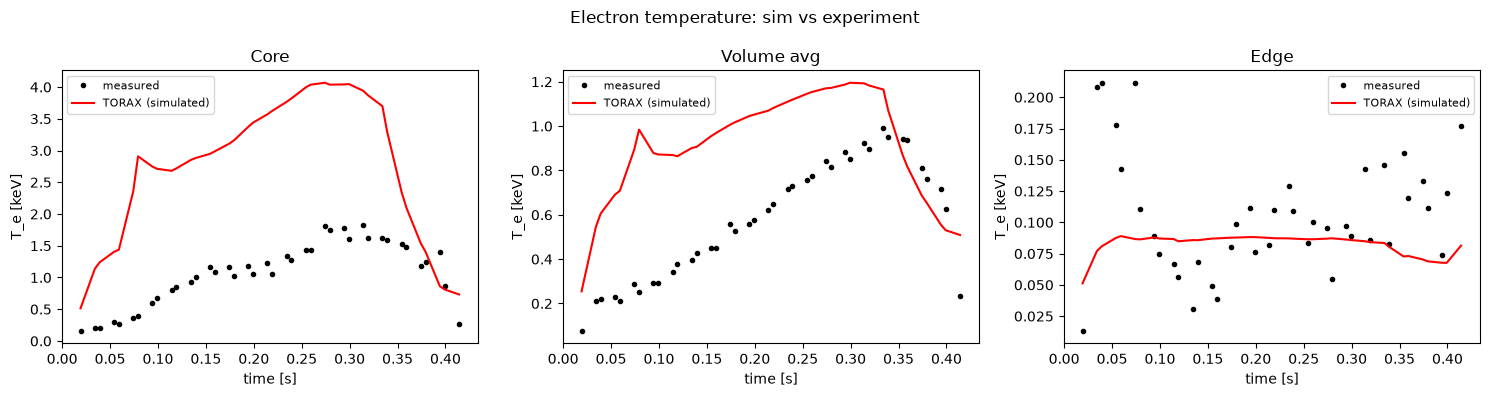

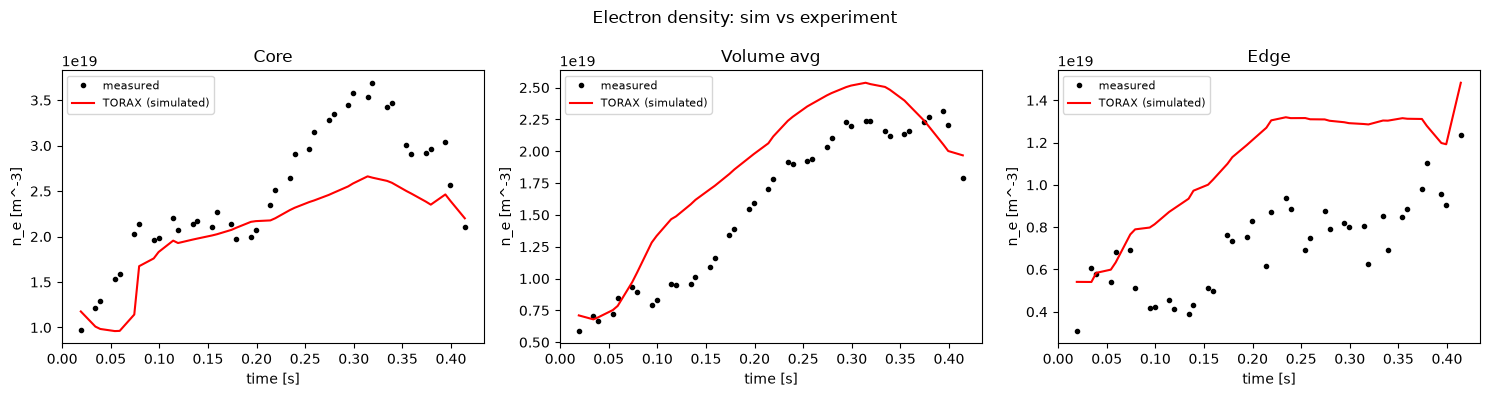

no CXRS Ti data in window, skipping Ti comparison


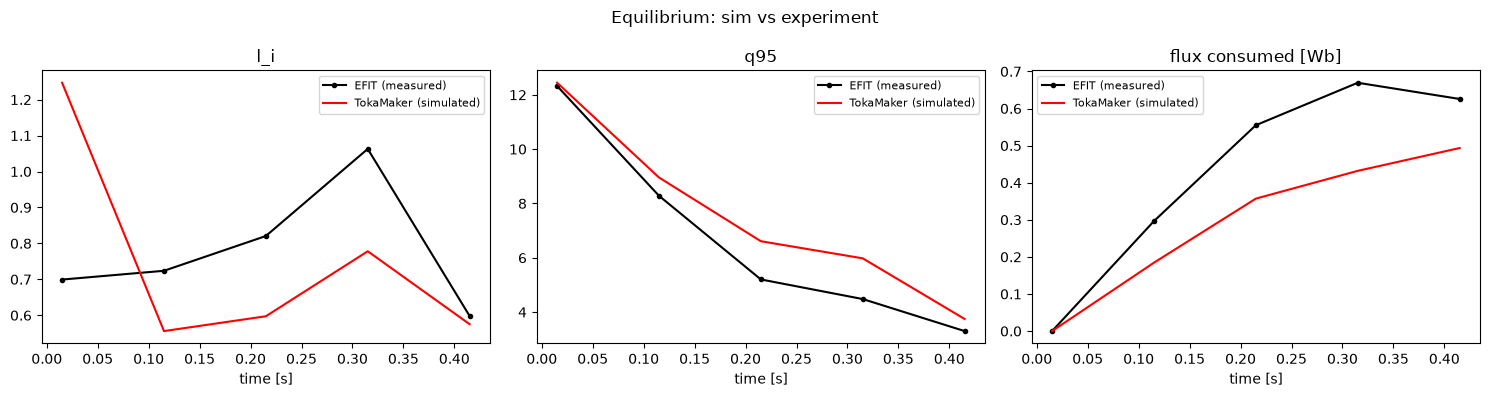

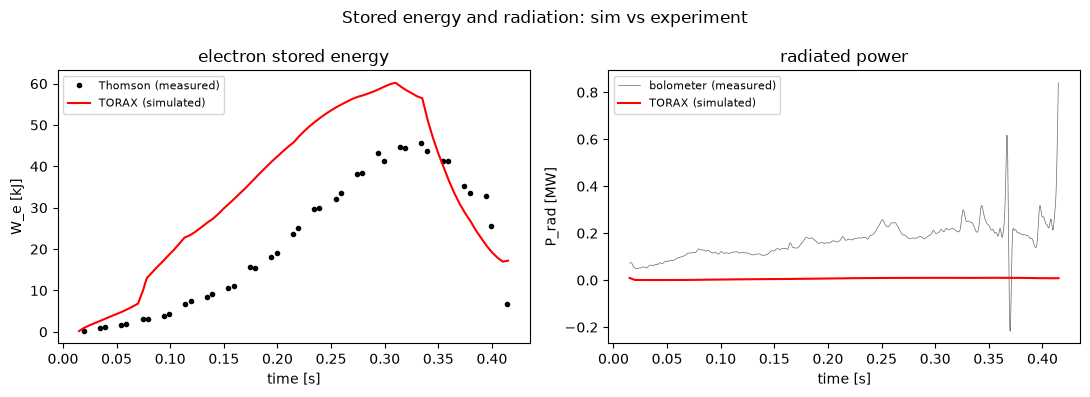

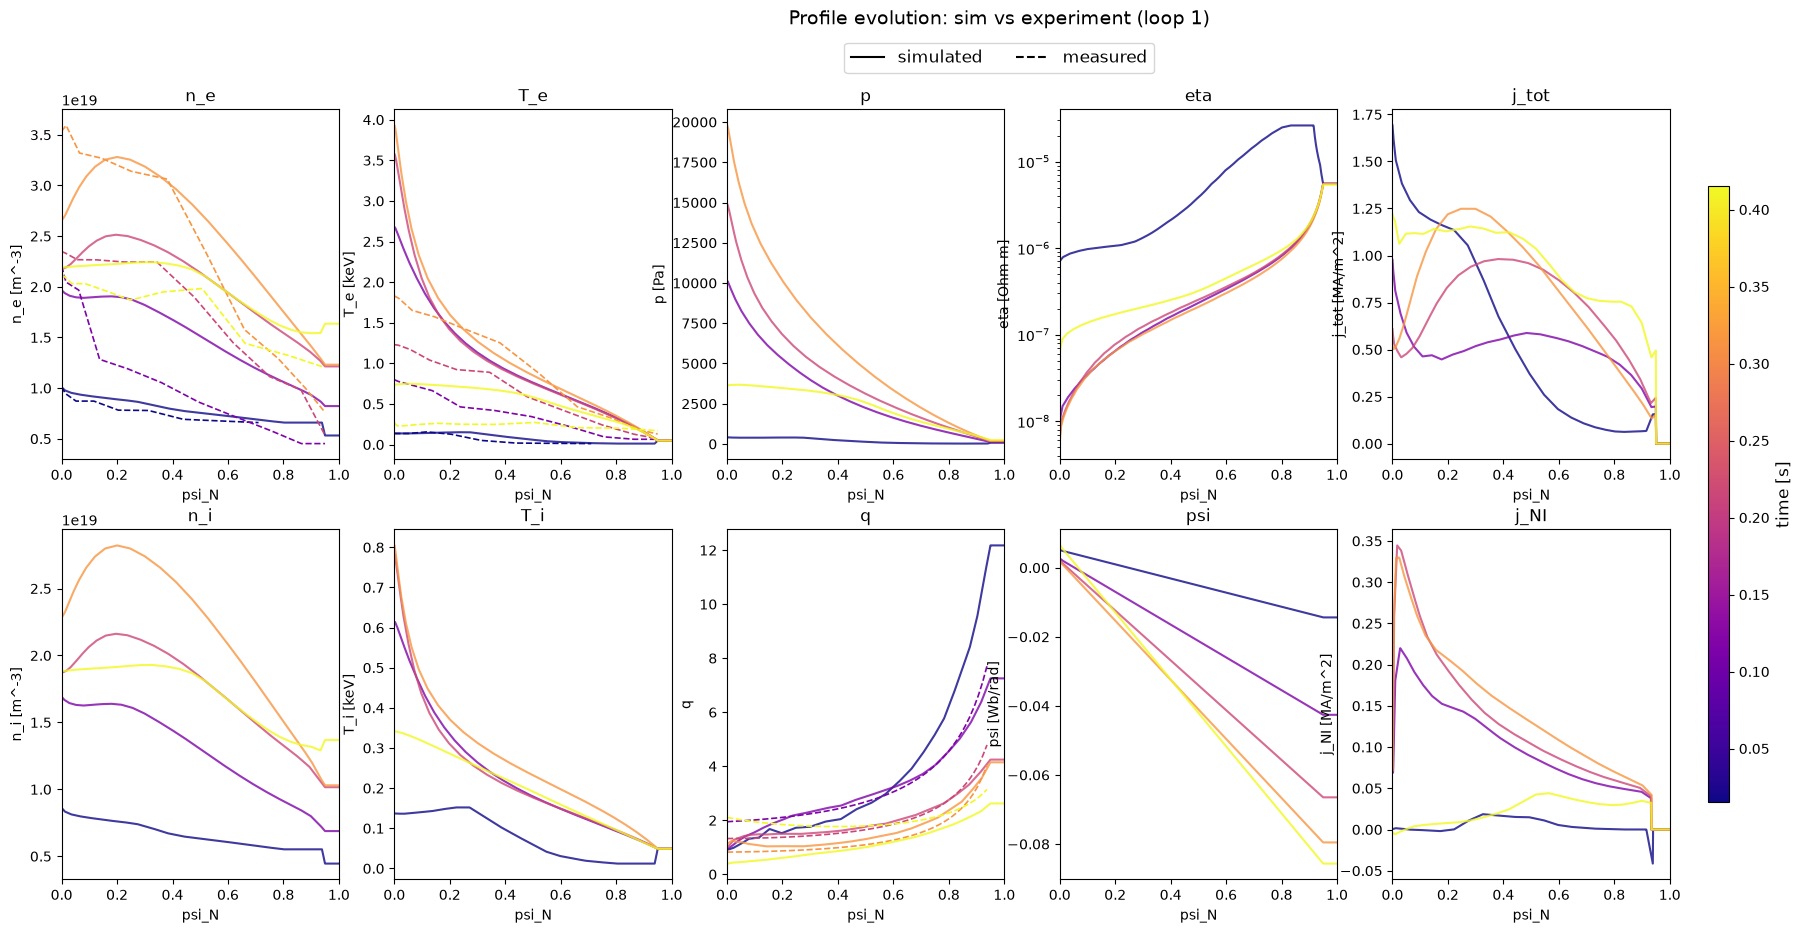

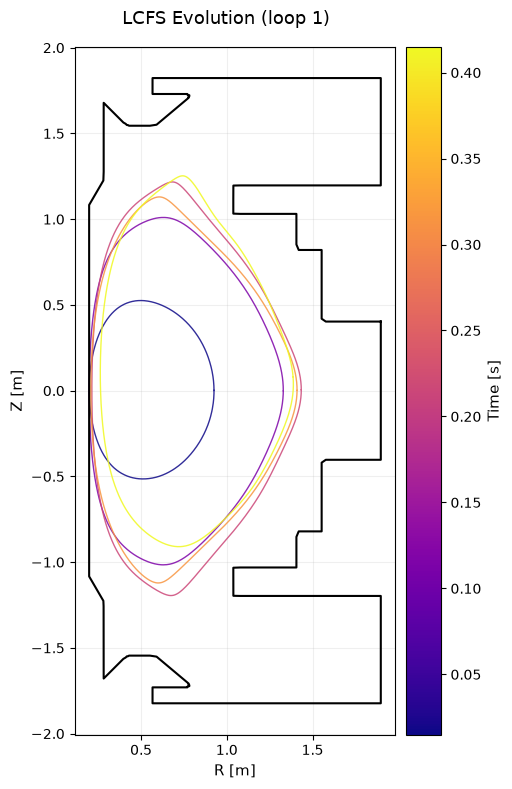

In [12]:
results = runMastPulses([14625], maxLoop = 1, verbose=False, plot=True)
for shotId, result in results.items():
    if result is not None:
        tmtx, diagnostics = result

# [14625, 14626, 30342] - tested
# usableIds = pd.read_csv('MAST_info/usable_pulses.csv')
# batchResults = runMastPulses(usableIds['shot_id'].tolist(), plot=False, verbose=False)